In [17]:
import numpy as np
import matplotlib.pyplot as plt

series_length = 1000
S = np.zeros((series_length, 1), 'd')
D = np.zeros((series_length, 1), 'd')

S[0] = 0.6
for t in range(1, series_length):
    D[t] = np.sin(np.pi/75. * t) - t/150.
    S[t] = (3.7+0.35*D[t]) * S[t-1] * (1 - S[t-1])

In [123]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: float,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.005,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: float

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + np.random.normal(scale=noise, size=1).item()

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i])# + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [124]:
np.random.normal(scale=0.1, size=1).item()

-0.0007486796125296242

In [125]:
S, _ = generate_data(
    n_timepoints=1_000,
    n_components=1,
    noise=0.1,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=1,
    firing_prop=0.05,
)

In [126]:
S = S.T

In [127]:
S.mean()

np.float64(0.015905033981547922)

In [128]:
S -= S.mean()

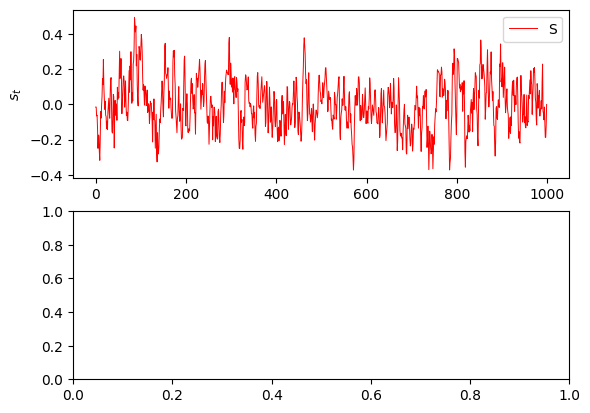

In [129]:
plt.subplot(211)
plt.plot(np.arange(series_length), S, 'r', linewidth=0.7, label="S")
plt.legend(loc='upper right')
plt.ylabel('$s_t$')
plt.subplot(212)
plt.show()

In [130]:
import mdp
timeframes = mdp.nodes.TimeFramesNode(4)
timeframed_S = timeframes.execute(S)

In [131]:
timeframed_S.shape

(997, 4)

In [132]:
timeframed_S.shape

(997, 4)

In [133]:
# cubic_expand = mdp.nodes.PolynomialExpansionNode(3)
# cubic_expanded_S = cubic_expand(timeframed_S)
sfa = mdp.nodes.SFANode(output_dim=1)
slow = sfa.execute(timeframed_S)

In [134]:
slow.shape

(997, 1)

In [135]:
import seaborn as sns

<Axes: >

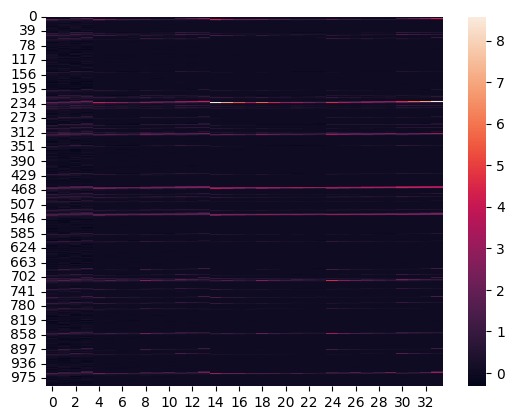

In [136]:
sns.heatmap(cubic_expanded_S)

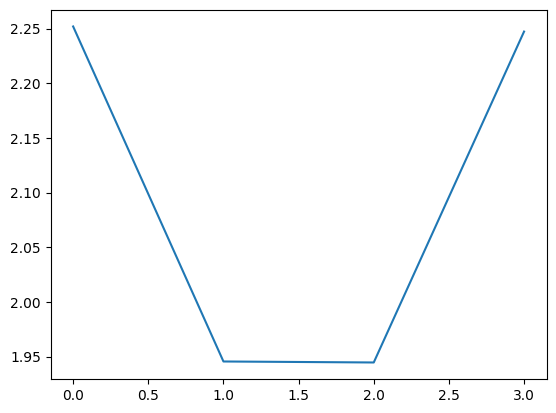

In [137]:
plt.plot(sfa.sf)

In [138]:
slow = slow.flatten()
padded_slow = np.concatenate([[slow[0]], slow, [slow[296]], [slow[296]]])
# rescaled_D = (D - np.mean(D, 0)) / np.std(D, 0)

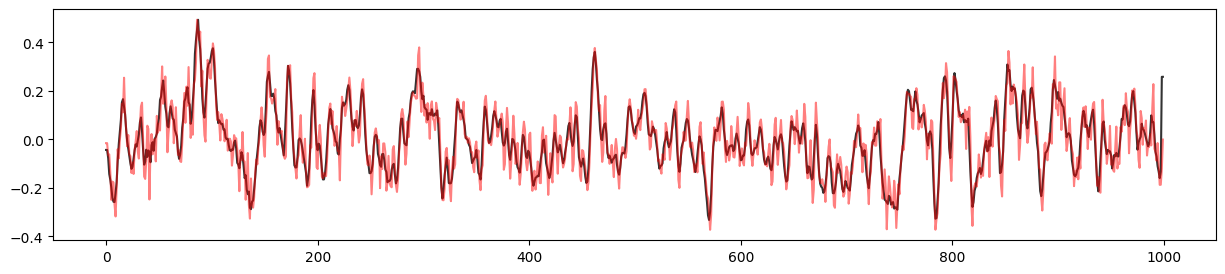

In [139]:
fig = plt.figure(figsize=(15, 3))
padded_slow /= padded_slow.max()
padded_slow *= S.max()
plt.plot(padded_slow, alpha=0.8, c="k")
plt.plot(S, alpha=0.5, c="r")
plt.show()